In [68]:
import pandas as pd
import sqlite3 as sq
import matplotlib as mpl
from matplotlib import rcParams
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
import fiona
import os
import io
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.functions import read_census_table, read_wp23_table

In [69]:
#TN we're reading in from UrbanSIM
tnurbansim = pd.read_csv(r"G:\3-GitHub\FCLUCS_Scenario_Planning\1-data\1-raw\2050RTP-TDMFeedback_2050Block.csv")
col_dict = {'sector_0': 'EMP_OTHER', 'sector_1': 'EMP_SERVICE', 'sector_2': 'EMP_RETAIL', 'sector_3': 'EMP_OFFICE', 'geo_level_id': 'GEO_ID',
               'sector_4': 'EMP_MEDICAL', 'sector_5': 'EMP_INDUSTRIAL', 'sector_6': 'EMP_GOVERNMENT', 'sector_7': 
               'EMP_FOODSERVICE', 'sector_8': 'EMP_EDUCATION', 'household_population': 'HHPOP', 'sum_total_households': 'HH', 'sum_total_jobs': 'EMP'}
tnurbansim = tnurbansim.rename(columns = col_dict)
tnurbansim_filt = tnurbansim[['GEO_ID', 'EMP']]
tnurbansim_filt['GEO_ID'] = tnurbansim_filt['GEO_ID'].astype(str)

In [70]:
tnurbansim_filt.head(2)

,GEO_ID,EMP
0,470831203003000,2.0
1,470831203003090,2.0


In [71]:
#KY we will take the same 2020 allocations that we used for 2023 base year to dole out the change in employment between this and the 2050 controls,
# so read in the base year with allocations as well as the WP smoothed totals
ky = gpd.read_file(r"G:\3-GitHub\FCLUCS_Scenario_Planning\1-data\2-interim\BaseYear.gpkg", layer="KY_EMP")
kycontrols = read_wp23_table('EmpSmoothed')

In [72]:
ky.columns

Index(['EMP', 'EMP_EDUCATION', 'EMP_FOODSERVICE', 'EMP_GOVERNMENT',
       'EMP_INDUSTRIAL', 'EMP_MEDICAL', 'EMP_OFFICE', 'EMP_OTHER',
       'EMP_RETAIL', 'EMP_SERVICE', 'GEO_ID', 'COUNTY', 'COUNTYFP',
       'EMP_ALLOC', 'EMP_EDUCATION_ALLOC', 'EMP_FOODSERVICE_ALLOC',
       'EMP_GOVERNMENT_ALLOC', 'EMP_INDUSTRIAL_ALLOC', 'EMP_MEDICAL_ALLOC',
       'EMP_OFFICE_ALLOC', 'EMP_RETAIL_ALLOC', 'EMP_SERVICE_ALLOC',
       'EMP_OTHER_ALLOC', 'geometry'],
      dtype='str')

In [73]:
ky.head(1)

,EMP,EMP_EDUCATION,EMP_FOODSERVICE,EMP_GOVERNMENT,EMP_INDUSTRIAL,EMP_MEDICAL,EMP_OFFICE,EMP_OTHER,EMP_RETAIL,EMP_SERVICE,...,EMP_EDUCATION_ALLOC,EMP_FOODSERVICE_ALLOC,EMP_GOVERNMENT_ALLOC,EMP_INDUSTRIAL_ALLOC,EMP_MEDICAL_ALLOC,EMP_OFFICE_ALLOC,EMP_RETAIL_ALLOC,EMP_SERVICE_ALLOC,EMP_OTHER_ALLOC,geometry
0,43,0,43,0,0,0,0,0,0,0,...,0.0,0.103359,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"POLYGON ((-87.68704 36.96876, -87.68666 36.969..."


In [74]:
ky = ky[['GEO_ID', 'COUNTY', 'COUNTYFP', 'EMP', 'EMP_ALLOC', 'geometry']]

In [75]:
kycontrols.head(1)

,NAME,Industry,2023,2024,2025,2026,2027,2028,2029,2030,...,2041,2042,2043,2044,2045,2046,2047,2048,2049,2050
0,"Cheatham County, Tennessee",Education,525.0,531.0,541.0,553.0,563.0,573.0,585.0,595.0,...,703.0,711.0,719.0,728.0,737.0,746.0,754.0,762.0,770.0,778.0


In [76]:
kycontrols['Industry'].unique()

<StringArray>
[                        'Education',                     'Food Services',
                        'Government',                        'Industrial',
                           'Medical',                            'Office',
                             'Other',                            'Retail',
                           'Service', 'Total employment (number of jobs)']
Length: 10, dtype: str

In [77]:
thelist = ['Trigg County, Kentucky', 'Christian County, Kentucky']
ky_totalemp = kycontrols.loc[kycontrols['Industry'] == "Total employment (number of jobs)"]
kyhorizon = ky_totalemp[['NAME', '2023', '2050']].loc[ky_totalemp['NAME'].isin(thelist)]
kyhorizon['EMP_GROWTH'] = kyhorizon['2050'] - kyhorizon['2023']

In [78]:
kyhorizon.head(2)

,NAME,2023,2050,EMP_GROWTH
19,"Christian County, Kentucky",71494.428571,78693.0,7198.571429
169,"Trigg County, Kentucky",5247.678571,5897.0,649.321429


In [79]:
trigghorizoncontrol = int(kyhorizon.loc[kyhorizon['NAME'] == 'Trigg County, Kentucky', '2050'].iloc[0])
christianhorizoncontrol = int(kyhorizon.loc[kyhorizon['NAME'] == 'Christian County, Kentucky', '2050'].iloc[0])
triggcontrol = int(kyhorizon.loc[kyhorizon['NAME'] == 'Trigg County, Kentucky', '2023'].iloc[0])
christiancontrol = int(kyhorizon.loc[kyhorizon['NAME'] == 'Christian County, Kentucky', '2023'].iloc[0])
triggdiff = int(kyhorizon.loc[kyhorizon['NAME'] == 'Trigg County, Kentucky', 'EMP_GROWTH'].iloc[0])
christiandiff = int(kyhorizon.loc[kyhorizon['NAME'] == 'Christian County, Kentucky', 'EMP_GROWTH'].iloc[0])

In [80]:
ky.head(1)

,GEO_ID,COUNTY,COUNTYFP,EMP,EMP_ALLOC,geometry
0,212219701001011,"Trigg County, Kentucky",21221,43,0.013316,"POLYGON ((-87.68704 36.96876, -87.68666 36.969..."


In [81]:
controls = {'Trigg County, Kentucky': trigghorizoncontrol,'Christian County, Kentucky': christianhorizoncontrol}

ky['EMP_2050'] = ((ky['EMP_ALLOC'])) * ky['COUNTY'].map(controls)

In [82]:
ky.head(1)

,GEO_ID,COUNTY,COUNTYFP,EMP,EMP_ALLOC,geometry,EMP_2050
0,212219701001011,"Trigg County, Kentucky",21221,43,0.013316,"POLYGON ((-87.68704 36.96876, -87.68666 36.969...",78.521971


In [83]:
# ============================================================
# 1. LOCAL GROWTH INPUTS
# ============================================================

# GEO_ID: additional employment expected by 2050
# Replace examples with actual stakeholder inputs.
# Leave empty if no local employment growth has been identified.

local_growth = {
    # "210470000000000": 150,
    # "212210000000000": 100,
}


def apply_local_growth(gdf, growth_dict):
    """
    Apply locally identified employment increases through 2050.

    Local growth is additive to the baseline employment and protected
    from background employment decline.

    Parameters
    ----------
    gdf : GeoDataFrame
        Census blocks with GEO_ID and EMP.

    growth_dict : dict
        {GEO_ID: additional employment}

    Returns
    -------
    GeoDataFrame
        With LOCAL_GROWTH and EMP_GROWTH_BASE columns.
    """

    gdf = gdf.copy()

    # Normalize GEOIDs
    gdf["GEO_ID"] = gdf["GEO_ID"].astype(str).str.strip()

    growth_dict = {
        str(k).strip(): v for k, v in growth_dict.items()
    }

    # Validate GEOIDs
    if gdf["GEO_ID"].duplicated().any():
        raise ValueError("Duplicate GEO_ID values found.")

    missing = set(growth_dict) - set(gdf["GEO_ID"])

    if missing:
        raise ValueError(
            f"Local growth GEOIDs not found: {sorted(missing)}"
        )

    # Validate growth values
    for geoid, value in growth_dict.items():
        if (
            not isinstance(value, (int, float, np.number))
            or not np.isfinite(value)
            or value < 0
        ):
            raise ValueError(
                f"Invalid local growth for {geoid}: {value}"
            )

    # Apply local growth
    gdf["LOCAL_GROWTH"] = (
        gdf["GEO_ID"]
        .map(growth_dict)
        .fillna(0)
        .astype(float)
    )

    # Adjusted employment used for density and adjacency
    gdf["EMP_GROWTH_BASE"] = (
        gdf["EMP"] + gdf["LOCAL_GROWTH"]
    )

    return gdf


# ============================================================
# 2. PREPARE DATA
# ============================================================

ky = ky.copy().reset_index(drop=True)

# Preserve original 2050 employment allocation
ky["EMP_2050_ORIG"] = ky["EMP_2050"].copy()

# Apply local growth BEFORE spatial calculations
ky = apply_local_growth(ky, local_growth)

# Calculate block area in square miles
ky_proj = ky.to_crs("EPSG:5070")

ky["AREA_SQMI"] = (
    ky_proj.geometry.area / 2_589_988.11
)

# Employment density including local development
ky["EMP_DENSITY"] = (
    ky["EMP_GROWTH_BASE"]
    / ky["AREA_SQMI"].replace(0, np.nan)
)

# Original zero-employment blocks
ky["ZERO_EMP"] = ky["EMP"] == 0


# ============================================================
# 3. IDENTIFY HIGH-DENSITY BLOCKS
# ============================================================

ky["HIGH_DENSITY"] = False

for county, group in ky.groupby("COUNTYFP"):

    # Use employed blocks in the adjusted distribution
    populated = group.loc[
        (group["EMP_GROWTH_BASE"] > 0) &
        (group["EMP_DENSITY"].notna())
    ]

    if populated.empty:
        continue

    threshold = populated["EMP_DENSITY"].quantile(0.75)

    ky.loc[
        populated.index,
        "HIGH_DENSITY"
    ] = (
        populated["EMP_DENSITY"] >= threshold
    )


# ============================================================
# 4. IDENTIFY ADJACENT ZERO-EMPLOYMENT BLOCKS
# ============================================================

ky["_block_id"] = np.arange(len(ky))

# Zero-employment blocks without specified local growth
zero_blocks = ky.loc[
    (ky["ZERO_EMP"]) &
    (ky["LOCAL_GROWTH"] == 0)
].copy()

high_blocks = ky.loc[
    ky["HIGH_DENSITY"]
].copy()

# Identify touching blocks (queen contiguity)
adjacent = gpd.sjoin(
    zero_blocks,
    high_blocks[
        [
            "_block_id",
            "COUNTYFP",
            "EMP_GROWTH_BASE",
            "geometry"
        ]
    ],
    how="inner",
    predicate="touches",
    lsuffix="zero",
    rsuffix="high"
)

# Keep adjacency within county boundaries
adjacent = adjacent.loc[
    adjacent["COUNTYFP_zero"] ==
    adjacent["COUNTYFP_high"]
].copy()

# Sum adjusted employment of neighboring high-density blocks
weights = (
    adjacent
    .groupby("_block_id_zero")["EMP_GROWTH_BASE_high"]
    .sum()
    .rename("ADJ_EMP")
)

ky["ADJ_EMP"] = (
    ky["_block_id"]
    .map(weights)
    .fillna(0)
)

# Eligible for additional spatial expansion
ky["ELIGIBLE"] = (
    ky["ZERO_EMP"] &
    (ky["LOCAL_GROWTH"] == 0) &
    (ky["ADJ_EMP"] > 0)
)


# ============================================================
# 5. ALLOCATE 2050 EMPLOYMENT
# ============================================================

# Start with baseline employment plus locally identified growth
ky["EMP_2050_FINAL"] = ky["EMP_2050_ORIG"].astype(float).copy()

ky["BACKGROUND_CHANGE"] = 0.0

for county, idx in ky.groupby("COUNTYFP").groups.items():

    # County controls
    emp_base = ky.loc[idx, "EMP"].sum()
    emp_2050 = ky.loc[idx, "EMP_2050_ORIG"].sum()

    # Local development
    local_total = ky.loc[idx, "LOCAL_GROWTH"].sum()

    # No local growth and no eligible expansion:
    # # Preserve the original 2050 geographic allocation
    if local_total == 0 and len(eligible_idx) == 0:
        continue

    # Remaining growth or decline
    remaining_change = (
        emp_2050 - emp_base - local_total
    )

    # Existing employment blocks without local growth
    # These are eligible for proportional increases or decreases
    existing_idx = ky.loc[idx].index[
        (ky.loc[idx, "EMP"] > 0) &
        (ky.loc[idx, "LOCAL_GROWTH"] == 0)
    ]

    # Zero-employment blocks eligible for spatial expansion
    eligible_idx = ky.loc[idx].index[
        ky.loc[idx, "ELIGIBLE"]
    ]

    # --------------------------------------------------------
    # POSITIVE REMAINING GROWTH
    # --------------------------------------------------------

    if remaining_change > 0:

        # Allocate 5% to eligible zero-employment blocks
        if len(eligible_idx) > 0:
            zero_growth = remaining_change * 0.05
        else:
            zero_growth = 0

        existing_growth = remaining_change - zero_growth

        # Distribute remaining growth to existing employment blocks
        if existing_growth > 0:

            weights = ky.loc[existing_idx, "EMP"]

            if weights.sum() <= 0:
                raise ValueError(
                    f"No employed blocks available for "
                    f"background growth in county {county}"
                )

            ky.loc[
                existing_idx, "BACKGROUND_CHANGE"
            ] = (
                weights / weights.sum()
                * existing_growth
            )

        # Allocate spatial expansion
        if zero_growth > 0:

            weights = ky.loc[eligible_idx, "ADJ_EMP"]

            ky.loc[
                eligible_idx, "BACKGROUND_CHANGE"
            ] = (
                weights / weights.sum()
                * zero_growth
            )

    # --------------------------------------------------------
    # NEGATIVE REMAINING GROWTH / DECLINE
    # --------------------------------------------------------

    elif remaining_change < 0:

        # Decline is assigned only to blocks without local growth
        weights = ky.loc[existing_idx, "EMP"]

        if weights.sum() <= 0:
            raise ValueError(
                f"No unprotected employment available "
                f"for decline in county {county}"
            )

        # Prevent decline exceeding available employment
        if abs(remaining_change) > weights.sum():
            raise ValueError(
                f"Required decline exceeds available "
                f"unprotected employment in county {county}. "
                f"Review local growth assumptions."
            )

        ky.loc[
            existing_idx, "BACKGROUND_CHANGE"
        ] = (
            weights / weights.sum()
            * remaining_change
        )

    # Apply background changes
    ky.loc[idx, "EMP_2050_FINAL"] += (
        ky.loc[idx, "BACKGROUND_CHANGE"]
    )


# ============================================================
# 6. QUALITY ASSURANCE
# ============================================================

qa = ky.groupby(["COUNTYFP", "COUNTY"]).agg(
    Emp_Base=("EMP", "sum"),
    Emp_2050_Control=("EMP_2050_ORIG", "sum"),
    Local_Growth=("LOCAL_GROWTH", "sum"),
    Background_Change=("BACKGROUND_CHANGE", "sum"),
    Emp_2050_Final=("EMP_2050_FINAL", "sum"),
    Zero_Emp_Blocks=("ZERO_EMP", "sum"),
    Eligible_Blocks=("ELIGIBLE", "sum")
)

qa["Net_Growth"] = (
    qa["Emp_2050_Control"] - qa["Emp_Base"]
)

qa["Control_Diff"] = (
    qa["Emp_2050_Final"] - qa["Emp_2050_Control"]
)

qa["Local_Share_of_2050"] = (
    qa["Local_Growth"]
    / qa["Emp_2050_Control"].replace(0, np.nan)
    * 100
)

# Check for negative block employment
if (ky["EMP_2050_FINAL"] < -1e-8).any():
    raise ValueError(
        "Negative block employment detected."
    )

# Confirm county controls are preserved
if not np.allclose(
    qa["Emp_2050_Final"],
    qa["Emp_2050_Control"],
    atol=1e-6,
    rtol=0
):
    raise ValueError(
        "Final employment allocations do not match county controls."
    )

print(qa.round(2))

# Remove temporary join identifier
ky = ky.drop(columns=["_block_id"])

                                     Emp_Base  Emp_2050_Control  Local_Growth  \
COUNTYFP COUNTY                                                                 
21047    Christian County, Kentucky     71494           78693.0           0.0   
21221    Trigg County, Kentucky          5246            5897.0           0.0   

                                     Background_Change  Emp_2050_Final  \
COUNTYFP COUNTY                                                          
21047    Christian County, Kentucky                0.0         78693.0   
21221    Trigg County, Kentucky                    0.0          5897.0   

                                     Zero_Emp_Blocks  Eligible_Blocks  \
COUNTYFP COUNTY                                                         
21047    Christian County, Kentucky                2                0   
21221    Trigg County, Kentucky                    1                0   

                                     Net_Growth  Control_Diff  \
COUNTYFP COUNTY     

In [84]:
ky.head(2)

,GEO_ID,COUNTY,COUNTYFP,EMP,EMP_ALLOC,geometry,EMP_2050,EMP_2050_ORIG,LOCAL_GROWTH,EMP_GROWTH_BASE,AREA_SQMI,EMP_DENSITY,ZERO_EMP,HIGH_DENSITY,ADJ_EMP,ELIGIBLE,EMP_2050_FINAL,BACKGROUND_CHANGE
0,212219701001011,"Trigg County, Kentucky",21221,43,0.013316,"POLYGON ((-87.68704 36.96876, -87.68666 36.969...",78.521971,78.521971,0.0,43.0,0.690140,62.306244,False,False,0.0,False,78.521971,0.0
1,212219701001022,"Trigg County, Kentucky",21221,7,0.001664,"POLYGON ((-87.73118 36.95788, -87.73111 36.958...",9.815246,9.815246,0.0,7.0,0.623634,11.224539,False,False,0.0,False,9.815246,0.0


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

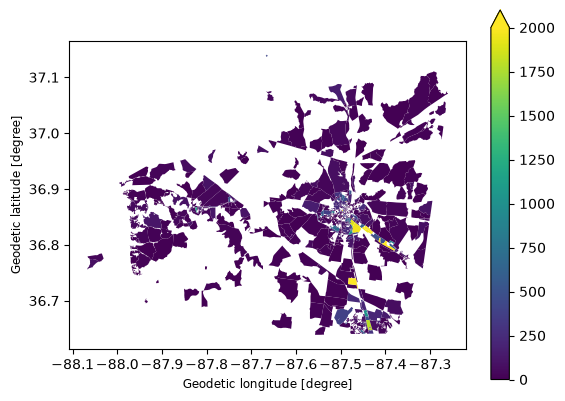

In [85]:
to_viz = 'EMP_2050_ORIG'
custom_low = 0
custom_high = 2000
ky.plot(column = to_viz, cmap="viridis", legend=True, 
        vmin= custom_low,
        #vmin = ky[to_viz].min(), 
        vmax= custom_high
        #vmax = ky[to_viz].max(),
        )